<a href="https://colab.research.google.com/github/abshajaofficial-dot/New-folder/blob/main/AI_Green_Grid_Optimizer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

⚡ Step 1: Generating Structured Smart-Grid Time Series Data...
🤖 Step 2: Training Random Forest Regressor for Demand Forecasting...
✅ Model Trained. Mean Absolute Error: 26.33 MW
🔋 Step 3: Simulating Automated Battery Grid Flexibility...


/tmp/ipykernel_638/2279130404.py:11: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  timesteps = pd.date_range(start="2026-01-01", periods=1000, freq="H")


📊 Step 4: Rendering System Performance Visualizations...


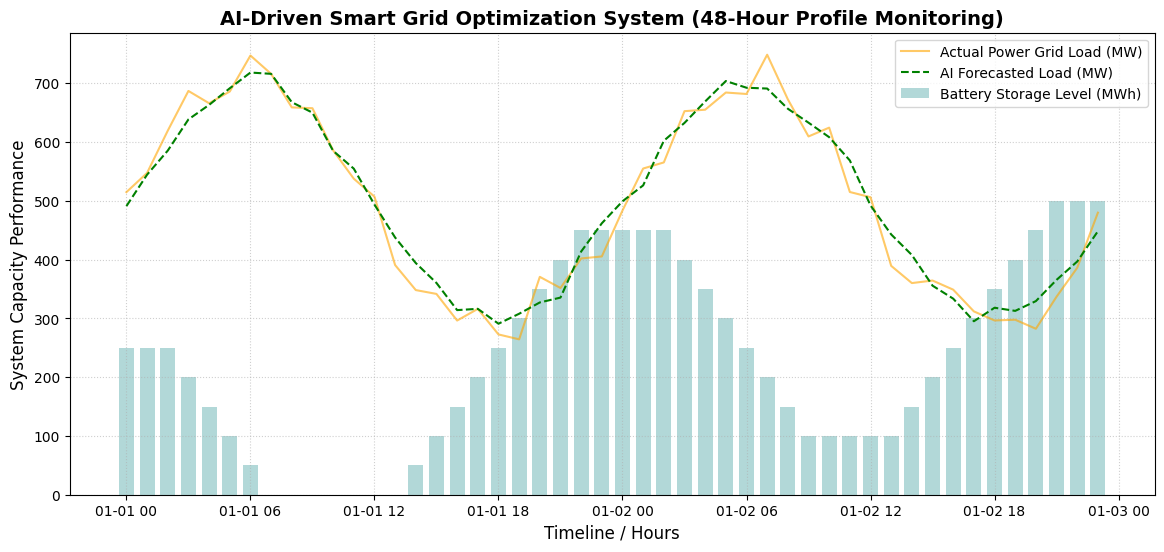

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

print("⚡ Step 1: Generating Structured Smart-Grid Time Series Data...")
# Generating mock real-world grid telemetry data for 1,000 consecutive hours
np.random.seed(42)
timesteps = pd.date_range(start="2026-01-01", periods=1000, freq="H")
# Simulating daily load cycles (sine wave) + unpredictable weather variance noise
mock_load = 500 + 200 * np.sin(timesteps.hour / 24 * 2 * np.pi) + np.random.normal(0, 30, 1000)
df = pd.DataFrame({'Timestamp': timesteps, 'Grid_Load_MW': mock_load})

# Feature Engineering: Extracting temporal patterns for the AI model
df['Hour'] = df['Timestamp'].dt.hour
df['DayOfWeek'] = df['Timestamp'].dt.dayofweek

X = df[['Hour', 'DayOfWeek']]
y = df['Grid_Load_MW']

print("🤖 Step 2: Training Random Forest Regressor for Demand Forecasting...")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Training the predictive framework
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Assessing structural accuracy
predictions = model.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
print(f"✅ Model Trained. Mean Absolute Error: {mae:.2f} MW")

print("🔋 Step 3: Simulating Automated Battery Grid Flexibility...")
battery_capacity_mwh = 500.0
current_charge = 250.0  # Initializing at 50% capacity
grid_threshold_high = 620.0  # Critical stress point
grid_threshold_low = 420.0   # Excess generation baseline

df['Predicted_Load'] = model.predict(X)
battery_status = []
grid_status_labels = []

# Simulate execution over a tight 48-hour testing horizon
for load in df['Predicted_Load'][:48]:
    if load > grid_threshold_high and current_charge >= 50:
        current_charge -= 50
        status = "Grid Stressed: Discharging Battery"
    elif load < grid_threshold_low and current_charge <= (battery_capacity_mwh - 50):
        current_charge += 50
        status = "Surplus Renewable Energy: Charging Battery"
    else:
        status = "Grid Balanced: Holding Charge"

    battery_status.append(current_charge)
    grid_status_labels.append(status)

print("📊 Step 4: Rendering System Performance Visualizations...")
# Plotting the results seamlessly inside your Colab output window
plt.figure(figsize=(14, 6))
plt.plot(df['Timestamp'][:48], df['Grid_Load_MW'][:48], label='Actual Power Grid Load (MW)', color='orange', alpha=0.6)
plt.plot(df['Timestamp'][:48], df['Predicted_Load'][:48], label='AI Forecasted Load (MW)', color='green', linestyle='--')
plt.bar(df['Timestamp'][:48], battery_status, label='Battery Storage Level (MWh)', color='teal', alpha=0.3, width=0.03)

plt.title('AI-Driven Smart Grid Optimization System (48-Hour Profile Monitoring)', fontsize=14, fontweight='bold')
plt.xlabel('Timeline / Hours', fontsize=12)
plt.ylabel('System Capacity Performance', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right')
plt.savefig('grid_optimization_chart.png', dpi=300, bbox_inches='tight')
plt.show()


